# Notebook 2: Variational Autoencoder (VAE)
**Assignment-02 | Activity A (CO3): Image Reconstruction** | Prepared by: Manmath (Research & Code Lead)

| | |
|---|---|
| **What to run** | Run all cells top to bottom (no edits needed). |
| **Where output appears** | Cell 5 shows original vs reconstructed images (saved as `A3_VAE_recon.png`); cell 6 shows images generated from random noise. |
| **Expected runtime** | about 2-3 min on T4 GPU |
| **Runtime setting** | Runtime -> Change runtime type -> **T4 GPU**, then **Runtime -> Run all** |

> Ready-made implementation written in Keras, tutorial style. Nothing is trained from scratch beyond a short demo run.

## 1. Idea in brief
A VAE's encoder outputs a **mean (mu)** and **log-variance** that define a Gaussian for each image. We sample `z = mu + sigma * eps` (the **reparameterisation trick**) and decode it.
The loss has two parts: **reconstruction loss** + **KL divergence** that pulls the latent space toward N(0, I). This makes the latent space smooth, so random samples decode into plausible images, at the cost of blurrier reconstructions.

## 2. Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (switch runtime to T4 GPU)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load data and choose input images
(Identical to the AE notebook, so both models see the same inputs.)

In [2]:
# Fashion-MNIST: 28x28 grayscale clothing images (clear textures, so blur is easy to see)
(x_train, _), (x_test, _) = keras.datasets.fashion_mnist.load_data()
x_train = np.expand_dims(x_train.astype("float32") / 255.0, -1)
x_test = np.expand_dims(x_test.astype("float32") / 255.0, -1)
print("train:", x_train.shape, "test:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (60000, 28, 28, 1) test: (10000, 28, 28, 1)


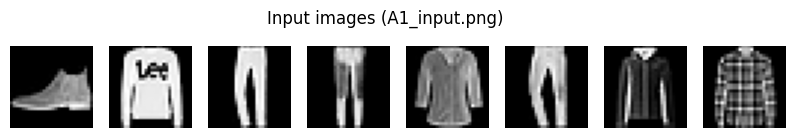

In [3]:
# SAME input images are used in the AE and VAE notebooks, so the comparison is fair.
SAMPLE_IDX = [0, 1, 2, 3, 4, 5, 6, 7]
inputs = x_test[SAMPLE_IDX]

# Optional: use your own image instead (set USE_CUSTOM_IMAGE = True and upload a file in Colab).
USE_CUSTOM_IMAGE = False
CUSTOM_PATH = "my_image.png"
if USE_CUSTOM_IMAGE:
    from PIL import Image
    img = Image.open(CUSTOM_PATH).convert("L").resize((28, 28))
    inputs = np.expand_dims(np.array(img, dtype="float32")[None] / 255.0, -1)

plt.figure(figsize=(10, 1.6))
for i in range(len(inputs)):
    plt.subplot(1, len(inputs), i + 1)
    plt.imshow(inputs[i].squeeze(), cmap="gray"); plt.axis("off")
plt.suptitle("Input images (A1_input.png)")
plt.savefig("A1_input.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Build the VAE

In [4]:
LATENT_DIM = 16   # same bottleneck size as the AE notebook

class Sampling(layers.Layer):
    """Reparameterisation trick: z = mu + sigma * epsilon."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

# Encoder: image -> (mu, log_var, z)
enc_in = keras.Input((28, 28, 1))
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(enc_in, [z_mean, z_log_var, z], name="encoder")

# Decoder: z -> image (same layout as the AE decoder)
decoder = keras.Sequential([
    layers.Input((LATENT_DIM,)),
    layers.Dense(7 * 7 * 64, activation="relu"),
    layers.Reshape((7, 7, 64)),
    layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid"),
], name="decoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    401,536 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      2,064 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      2,064 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 424,480 (1.62 MB)

 Trainable params: 424,480 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.loss_tracker, self.recon_tracker, self.kl_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            mu, log_var, z = self.encoder(data)
            recon = self.decoder(z)
            # reconstruction term: pixel-wise binary cross-entropy summed per image
            recon_loss = tf.reduce_mean(tf.reduce_sum(
                keras.losses.binary_crossentropy(data, recon), axis=(1, 2)))
            # KL( q(z|x) || N(0, I) ) in closed form
            kl_loss = -0.5 * tf.reduce_mean(tf.reduce_sum(
                1 + log_var - tf.square(mu) - tf.exp(log_var), axis=1))
            total = recon_loss + self.beta * kl_loss
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.loss_tracker.update_state(total)
        self.recon_tracker.update_state(recon_loss)
        self.kl_tracker.update_state(kl_loss)
        return {m.name: m.result() for m in self.metrics}

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

## 5. Train and reconstruct (screenshot the reconstruction cell)

Epoch 1/20
469/469 - 20s - 43ms/step - kl_loss: 12.1621 - loss: 295.6003 - recon_loss: 283.4381
Epoch 2/20
469/469 - 4s - 8ms/step - kl_loss: 13.6701 - loss: 251.6355 - recon_loss: 237.9655
Epoch 3/20
469/469 - 4s - 8ms/step - kl_loss: 14.0720 - loss: 246.8495 - recon_loss: 232.7775
Epoch 4/20
469/469 - 3s - 7ms/step - kl_loss: 14.3533 - loss: 244.4326 - recon_loss: 230.0795
Epoch 5/20
469/469 - 3s - 7ms/step - kl_loss: 14.5129 - loss: 243.0349 - recon_loss: 228.5220
Epoch 6/20
469/469 - 3s - 7ms/step - kl_loss: 14.6088 - loss: 242.2566 - recon_loss: 227.6479
Epoch 7/20
469/469 - 3s - 7ms/step - kl_loss: 14.6673 - loss: 241.4497 - recon_loss: 226.7822
Epoch 8/20
469/469 - 3s - 7ms/step - kl_loss: 14.7031 - loss: 240.8809 - recon_loss: 226.1778
Epoch 9/20
469/469 - 3s - 7ms/step - kl_loss: 14.7662 - loss: 240.4904 - recon_loss: 225.7241
Epoch 10/20
469/469 - 3s - 7ms/step - kl_loss: 14.8015 - loss: 240.0521 - recon_loss: 225.2505
Epoch 11/20
469/469 - 5s - 11ms/step - kl_loss: 14.8312 -

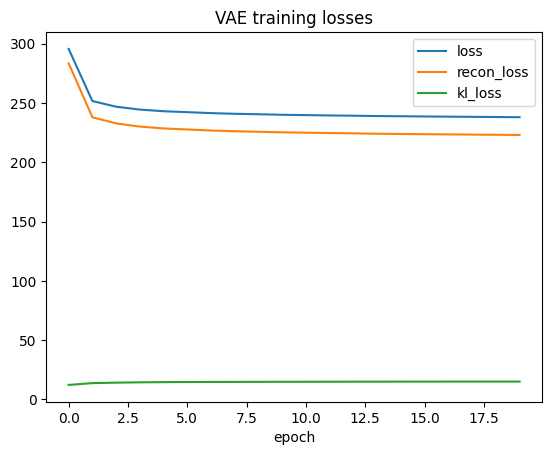

In [6]:
EPOCHS = 20
start = time.time()
history = vae.fit(x_train, epochs=EPOCHS, batch_size=128, verbose=2)
train_time = time.time() - start
print(f"Training time: {train_time:.1f} s")

for k in ["loss", "recon_loss", "kl_loss"]:
    plt.plot(history.history[k], label=k)
plt.xlabel("epoch"); plt.title("VAE training losses"); plt.legend(); plt.show()

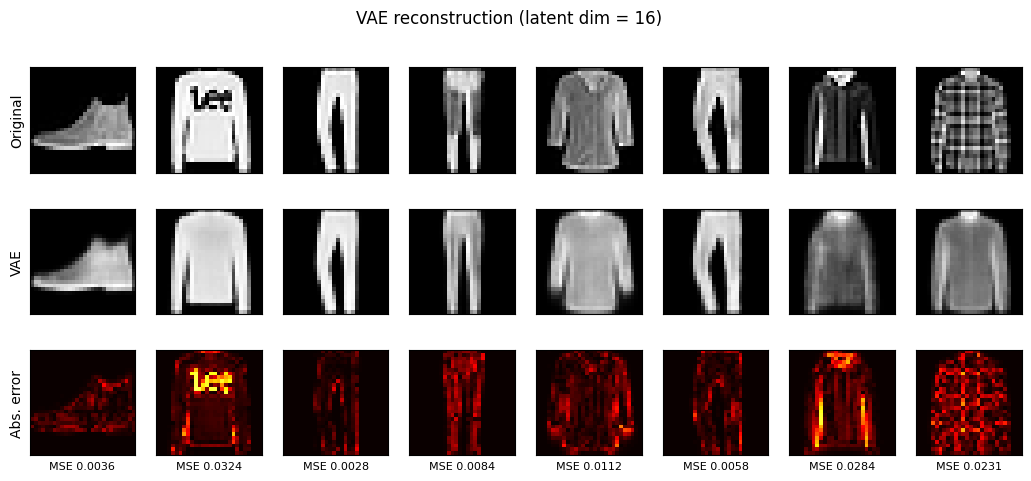

Average MSE over the shown images: 0.01447


In [7]:
z_mean, _, _ = encoder.predict(inputs, verbose=0)   # use the mean (no sampling noise) for reconstruction
recon = decoder.predict(z_mean, verbose=0)
mse = np.mean((inputs - recon) ** 2, axis=(1, 2, 3))

n = len(inputs)
fig, axes = plt.subplots(3, n, figsize=(1.6 * n, 5.2))
for i in range(n):
    axes[0, i].imshow(inputs[i].squeeze(), cmap="gray")
    axes[1, i].imshow(recon[i].squeeze(), cmap="gray")
    axes[2, i].imshow(np.abs(inputs[i] - recon[i]).squeeze(), cmap="hot", vmin=0, vmax=1)
    axes[2, i].set_xlabel(f"MSE {mse[i]:.4f}", fontsize=8)
    for r in range(3):
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("VAE"); axes[2, 0].set_ylabel("Abs. error")
fig.suptitle("VAE reconstruction (latent dim = %d)" % LATENT_DIM)
plt.savefig("A3_VAE_recon.png", dpi=200, bbox_inches="tight"); plt.show()
print("Average MSE over the shown images: %.5f" % mse.mean())

## 6. Generate *new* images from random noise
The KL term shaped the latent space, so sampling `z ~ N(0, I)` and decoding gives plausible new items (compare with the AE notebook, where this failed).

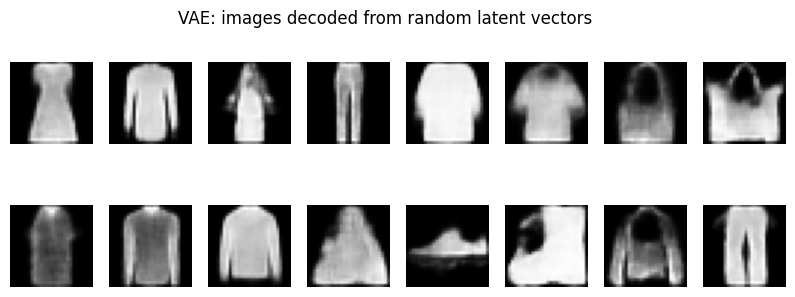

In [8]:
z = np.random.normal(size=(16, LATENT_DIM)).astype("float32")
samples = decoder.predict(z, verbose=0)
plt.figure(figsize=(10, 3.4))
for i in range(16):
    plt.subplot(2, 8, i + 1); plt.imshow(samples[i].squeeze(), cmap="gray"); plt.axis("off")
plt.suptitle("VAE: images decoded from random latent vectors"); plt.savefig("A3b_VAE_samples.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Observation notes (copy into the Observation Table)
- Blurring: ______  | Distortion: ______  | Loss of detail: ______
- Compared with AE (same inputs): ______
- Random samples: ______